# ДЗ 1. Прогнозирование продаж: анализ и предобработка временного ряда
Датасет: [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail) — транзакции британского онлайн-магазина подарков, 01.12.2010–09.12.2011.
Вся логика — в `retail_ts.py`, ноутбук вызывает функции и показывает результаты.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import retail_ts as rt

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 100

## 1. Витрина данных
### 1.1 Структура

In [2]:
df = rt.load_raw()
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  str           
 1   StockCode    541909 non-null  str           
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(1), str(3)
memory usage: 33.1+ MB


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Одна строка — позиция в чеке. Для ряда нужны: `StockCode` (товар), `InvoiceDate` (дата), `Quantity` (показатель продаж — штуки).
`InvoiceNo` нужен, чтобы отличать отмены, `CustomerID` — чтобы сопоставлять отмены с заказами.

In [3]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


Отрицательные `Quantity` и `UnitPrice`, а также максимум 80 995 шт. — первые признаки того, что в данных есть не только продажи.

### 1.2 Качество сырых данных

In [4]:
rt.quality_report(df)

,строк,"доля, %"
Отмены (InvoiceNo начинается с C),9288,1.71
Корректировки долга (InvoiceNo начинается с A),3,0.00
Quantity < 0 без отмены (списания),1336,0.25
UnitPrice <= 0,2517,0.46
"Служебные StockCode (POST, M, DOT, ...)",2995,0.55
Пустой Description,1454,0.27
Пустой CustomerID,135080,24.93
Полные дубликаты строк,5268,0.97


- **Отмены** (`C...`) и **списания** (отрицательное количество без отмены, цена 0, описание вроде «damaged», «thrown away») — это не спрос.
- **Служебные коды** (`POST` — доставка, `M` — ручная правка, `DOT`, `BANK CHARGES`, `AMAZONFEE`) — не товары.
- **Пустой `CustomerID`** у четверти строк — для ряда продаж не важно, строки оставляем.
- **Полные дубликаты** — ~1 %, разберём ниже.

In [5]:
dups = df[df.duplicated(keep=False)]
multi = df.groupby(["InvoiceNo", "StockCode"]).size().gt(1).sum()
print(f"Дубликаты встречаются в {dups.InvoiceNo.nunique()} чеках, все — внутри одного чека в одну минуту")
print(f"Пар «чек–товар» с несколькими строками (в т.ч. с разным количеством): {multi}")
dups.sort_values(["InvoiceNo", "StockCode"]).head(6)

Дубликаты встречаются в 1933 чеках, все — внутри одного чека в одну минуту
Пар «чек–товар» с несколькими строками (в т.ч. с разным количеством): 9694


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom


Несколько строк одного товара в чеке — обычное дело (товар добавили в корзину дважды, в том числе с разным количеством).
Полный дубликат так же правдоподобен как повторное добавление → **оставляем**.

### 1.3 Аномально крупные заказы и отмены

In [6]:
cols = ["InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate", "UnitPrice", "CustomerID"]
big = df.loc[df.Quantity.abs().nlargest(6).index, cols].sort_values("InvoiceDate")
big

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0
225529,556690,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0.00,NaN
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,0.00,13256.0
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0


**Отмены.** Два крупнейших заказа (80 995 и 74 215 шт.) тот же клиент отменил через 10–15 минут: это ошибки ввода, спроса не было.
Остальные отмены в основном являются возвратами через недели. Покупка при этом состоялась, значит спрос в день покупки был.

**Правило:** продажу убираем, только если её отменили **в тот же день** (тот же клиент, товар и количество). Возвраты не трогаем.

In [7]:
for same_day in (True, False):
    _, n = rt.drop_cancelled_orders(df, same_day=same_day)
    print(f"same_day={same_day}: убрано продаж {n}")

same_day=True: убрано продаж 591


same_day=False: убрано продаж 2860


### 1.4 Календарь работы магазина

In [8]:
cal = rt.store_calendar(df)
print(f"Дней в периоде: {len(cal)}, рабочих: {cal.is_open.sum()}, нерабочих: {(~cal.is_open).sum()}")
cal[~cal.is_open].weekday.value_counts()

Дней в периоде: 374, рабочих: 305, нерабочих: 69


weekday
Saturday     53
Monday        6
Friday        4
Sunday        3
Tuesday       1
Wednesday     1
Thursday      1
Name: count, dtype: int64

In [9]:
cal[~cal.is_open & (cal.weekday != 'Saturday')]

,is_open,weekday
date,,
2010-12-24,False,Friday
2010-12-26,False,Sunday
2010-12-27,False,Monday
2010-12-28,False,Tuesday
2010-12-29,False,Wednesday
2010-12-30,False,Thursday
2010-12-31,False,Friday
2011-01-02,False,Sunday
2011-01-03,False,Monday


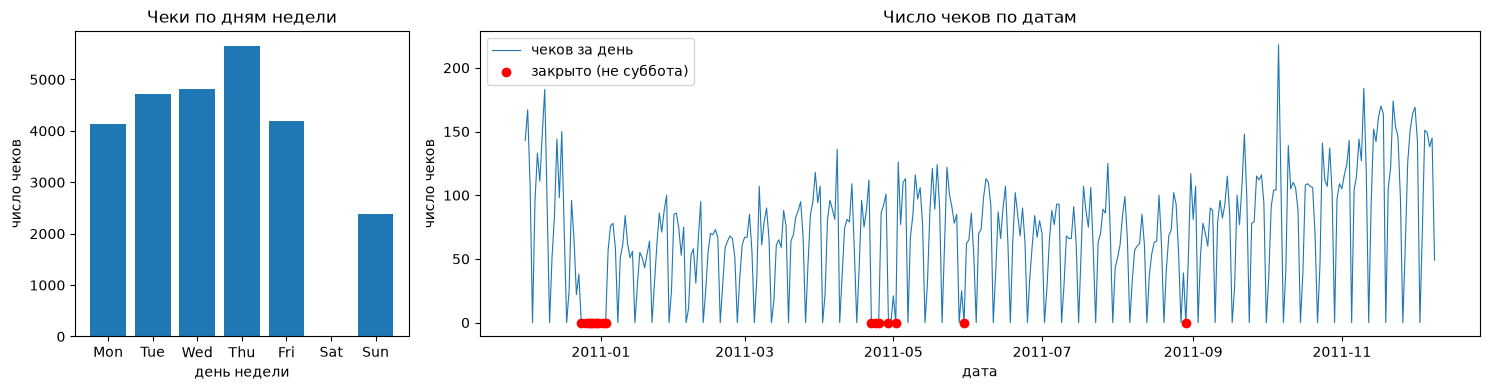

In [10]:
rt.plot_store_activity(df, cal);

- **По субботам магазин не работает никогда** — 0 чеков за весь период.
- Кроме суббот закрыт на **Рождество** (24.12.2010–03.01.2011) и **госпраздники Великобритании**: Пасха (22–25.04), свадьба принца Уильяма (29.04), May Day (02.05), Spring и Summer Bank Holiday (30.05, 29.08).
- В воскресенье чеков заметно меньше, чем в будни.

**Запомним для ряда:** магазин закрыт → наблюдения нет; магазин открыт, но товар не купили → ноль.

### 1.5 Границы периода

In [11]:
print("Первая транзакция:", df.InvoiceDate.min())
print("Последняя транзакция:", df.InvoiceDate.max())

Первая транзакция: 2010-12-01 08:26:00
Последняя транзакция: 2011-12-09 12:50:00


Декабрь 2011 есть только до 9-го → отрезаем. Анализируем **01.12.2010–30.11.2011**, ровно 12 месяцев.
Месячный ряд — 12 точек: **годовую сезонность доказать нельзя** (нужно ≥ 2 цикла). Проверяемая сезонность — недельная.

### 1.6 Очищенные продажи

In [12]:
END = "2011-12-01"
cal = cal[cal.index < END]
sales = rt.clean_sales(df)
sales = sales[sales.date < END]
open_days = cal.index[cal.is_open]

raw_pos = df[(df.Quantity > 0) & (df.InvoiceDate < END)]
pd.DataFrame({"строк": [len(raw_pos), len(sales)], "шт.": [raw_pos.Quantity.sum(), sales.Quantity.sum()]},
             index=["сырые положительные", "после очистки"])

,строк,шт.
сырые положительные,506150,5345929
после очистки,502142,5171105


### 1.7 Выбор товара

Обозначим хорошего кандидата: продаётся почти каждый рабочий день все 12 месяцев, много клиентов, ни один день не даёт заметной доли годовых продаж (`макс_день_доля`).
`85123A` исключён.

In [13]:
stats = rt.product_stats(sales, open_days)
stats.head(15)

,описание,шт_всего,выручка,доля_дней_с_продажами,месяцев,клиентов,CV_дневной,макс_день_доля,цена_медиана
StockCode,,,,,,,,,
85123A,WHITE HANGING HEART T-LIGHT HOLDER,36833,102257.0,1.000,12,850,1.97,0.085,2.95
22423,REGENCY CAKESTAND 3 TIER,13313,167143.0,0.987,12,871,1.04,0.027,12.75
84879,ASSORTED COLOUR BIRD ORNAMENT,35126,56924.0,0.983,12,666,1.93,0.096,1.69
85099B,JUMBO BAG RED RETROSPOT,46728,90980.0,0.983,12,625,1.18,0.031,2.08
21212,PACK OF 72 RETROSPOT CAKE CASES,35936,20739.0,0.976,12,628,1.54,0.043,0.55
20725,LUNCH BAG RED RETROSPOT,18955,34974.0,0.976,12,524,0.99,0.023,1.65
22457,NATURAL SLATE HEART CHALKBOARD,8244,25477.0,0.973,12,574,0.90,0.021,2.95
22960,JAM MAKING SET WITH JARS,8441,35835.0,0.966,12,567,1.19,0.029,4.25
22666,RECIPE BOX PANTRY YELLOW DESIGN,7787,24560.0,0.963,12,467,2.06,0.083,2.95


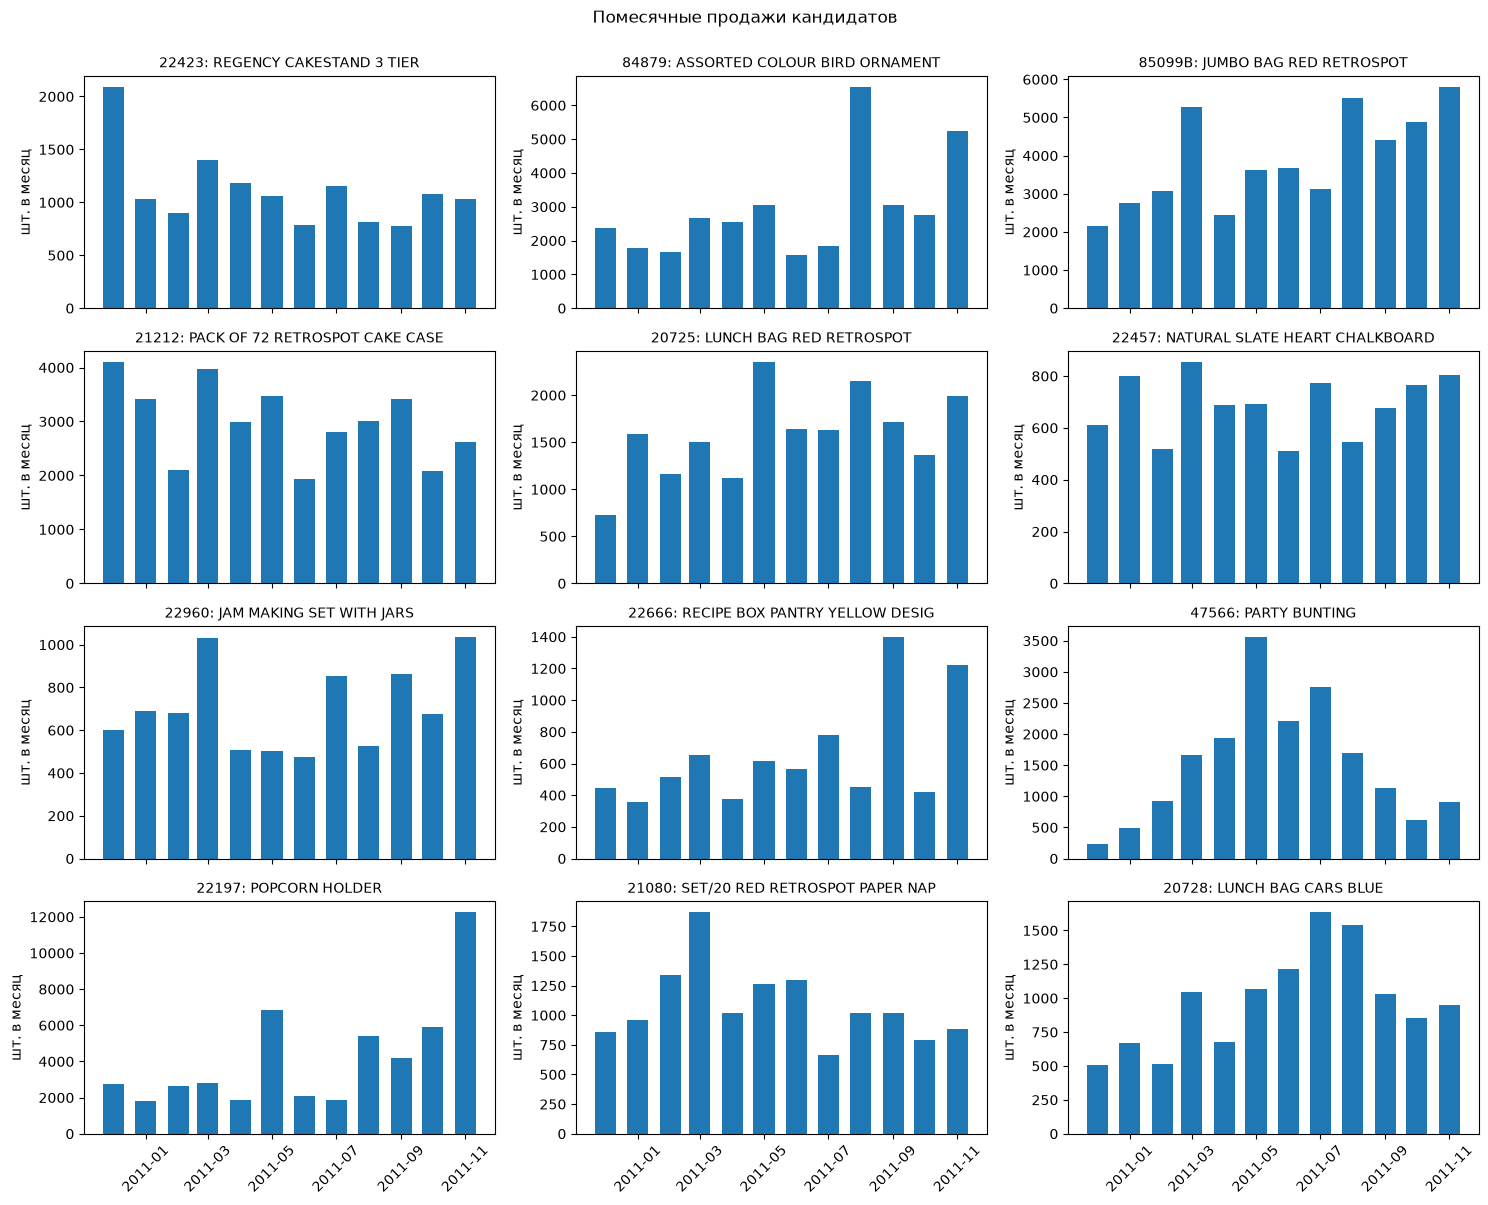

In [14]:
candidates = stats.index[:13].drop("85123A", errors="ignore")[:12].tolist()
rt.plot_monthly_grid(sales, candidates);

**Выбрали `85099B JUMBO BAG RED RETROSPOT`**: продажи в 98 % рабочих дней, 625 клиентов, самый крупный день — 3 % годовых продаж, виден растущий тренд.

## 2. Временной ряд и качество данных
### 2.1 Ряды: день, неделя, месяц

- **День:** календарь из 6 дней (вс–пт). Суббот в данных нет вообще — не считаем пропуском, просто удаляем. Праздник → `NaN`, рабочий день без продаж → `0`.
- **Неделя (пн–вс) и месяц:** число рабочих дней разное (праздники, Рождество), поэтому основной показатель — **среднее за рабочий день**, сумма — доп.

In [15]:
CODE = "85099B"
daily = rt.build_daily(sales, CODE, cal)
weekly = rt.aggregate(daily, "W-SUN")
monthly = rt.aggregate(daily, "MS")
print(f"Дней: {len(daily)}, недель: {len(weekly)}, месяцев: {len(monthly)}")
monthly

Дней: 313, недель: 53, месяцев: 12


,sum,open_days,per_day
date,,,
2010-12-01,2151.0,20,107.550000
2011-01-01,2747.0,24,114.458333
2011-02-01,3080.0,24,128.333333
2011-03-01,5280.0,27,195.555556
2011-04-01,2456.0,21,116.952381
2011-05-01,3621.0,25,144.840000
2011-06-01,3681.0,26,141.576923
2011-07-01,3128.0,26,120.307692
2011-08-01,5502.0,26,211.615385


### 2.2 Пропуски

In [16]:
print("Пропуски в дневном ряде (праздники):")
display(rt.nan_runs(daily))
print("Недели без рабочих дней:")
display(weekly[weekly.per_day.isna()])
rt.zero_stats(daily)

Пропуски в дневном ряде (праздники):


,начало,конец,длина
0,2010-12-24,2011-01-03,9
1,2011-04-22,2011-04-25,3
2,2011-04-29,2011-04-29,1
3,2011-05-02,2011-05-02,1
4,2011-05-30,2011-05-30,1
5,2011-08-29,2011-08-29,1


Недели без рабочих дней:


,sum,open_days,per_day
date,,,
2011-01-02,NaN,0,NaN


наблюдений           297.000
нулей                  5.000
доля нулей             0.017
макс. серия нулей      1.000
dtype: float64

- 16 пропущенных дней — только праздники, самый длинный разрыв — Рождество (9 рабочих дней подряд).
- Нулей всего 5 из 297 рабочих дней (< 2 %), подряд не больше одного считаем, что спрос **регулярный**.
- В недельном ряде пропущена одна неделя (27.12–02.01: магазин закрыт целиком), в месячном пропусков нет.

**Решение:** нулями пропуски не заполняем - продаж не было, т.к. магазин был закрыт. Для методов, которым нужен ряд без пропусков (STL, тесты стационарности), — **линейная интерполяция**: короткие разрывы, а ряд плотный, без нулей.

In [17]:
daily_f = daily.interpolate()
weekly_f = weekly.per_day.interpolate()
monthly_f = monthly.per_day

### 2.3 Выбросы

Два метода:
- **IQR** — глобальный порог по всему ряду. Простой, но не учитывает тренд: при росте продаж поздние точки чаще попадают в выбросы.
- **Фильтр Хампеля** — скользящая медиана ± 3·MAD в окне. Порог локальный, устойчивый к самим выбросам.

Дневные продажи, Hampel (окно 7): 31 выбросов
Дневные продажи, IQR: 14 выбросов


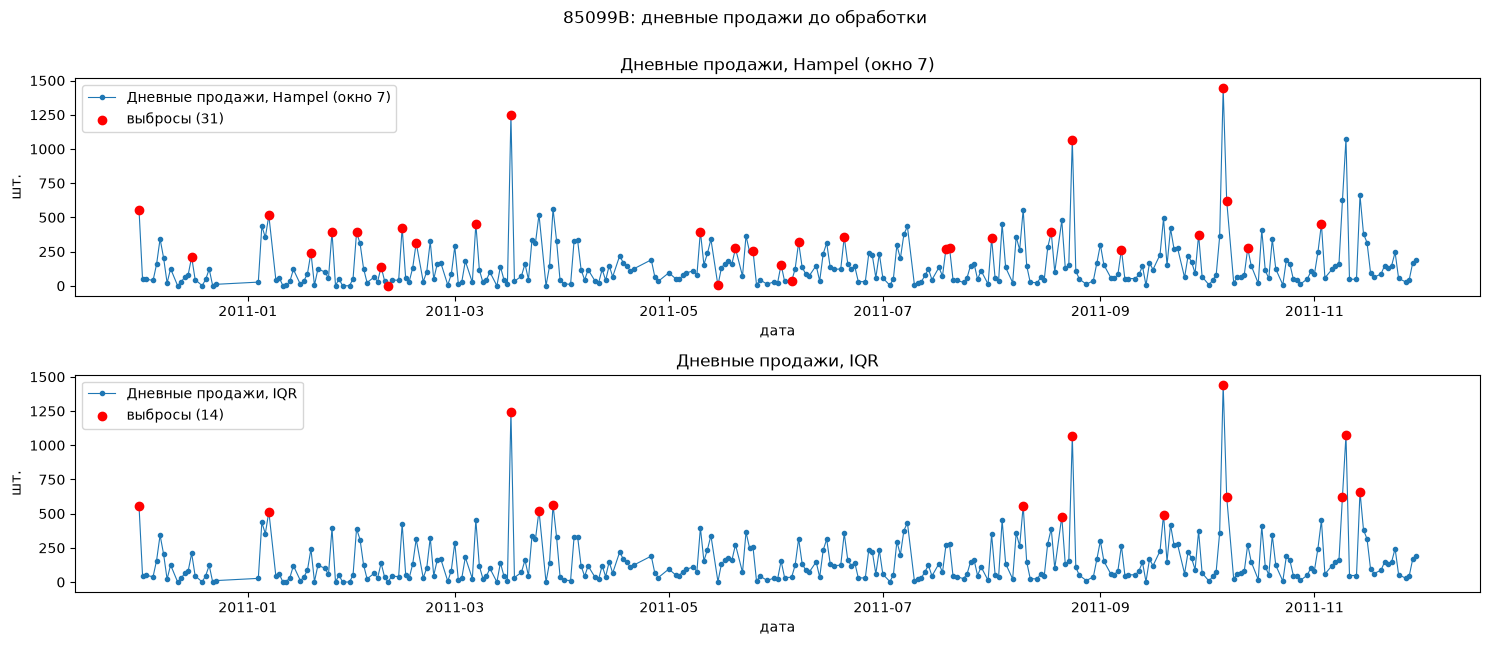

In [18]:
obs = daily.dropna()
out_daily = {"Дневные продажи, Hampel (окно 7)": rt.hampel_outliers(obs, window=7),
             "Дневные продажи, IQR": rt.iqr_outliers(obs)}
for name, mask in out_daily.items():
    print(f"{name}: {mask.sum()} выбросов")
rt.plot_series({k: obs for k in out_daily}, outliers=out_daily,
               title=f"{CODE}: дневные продажи до обработки");

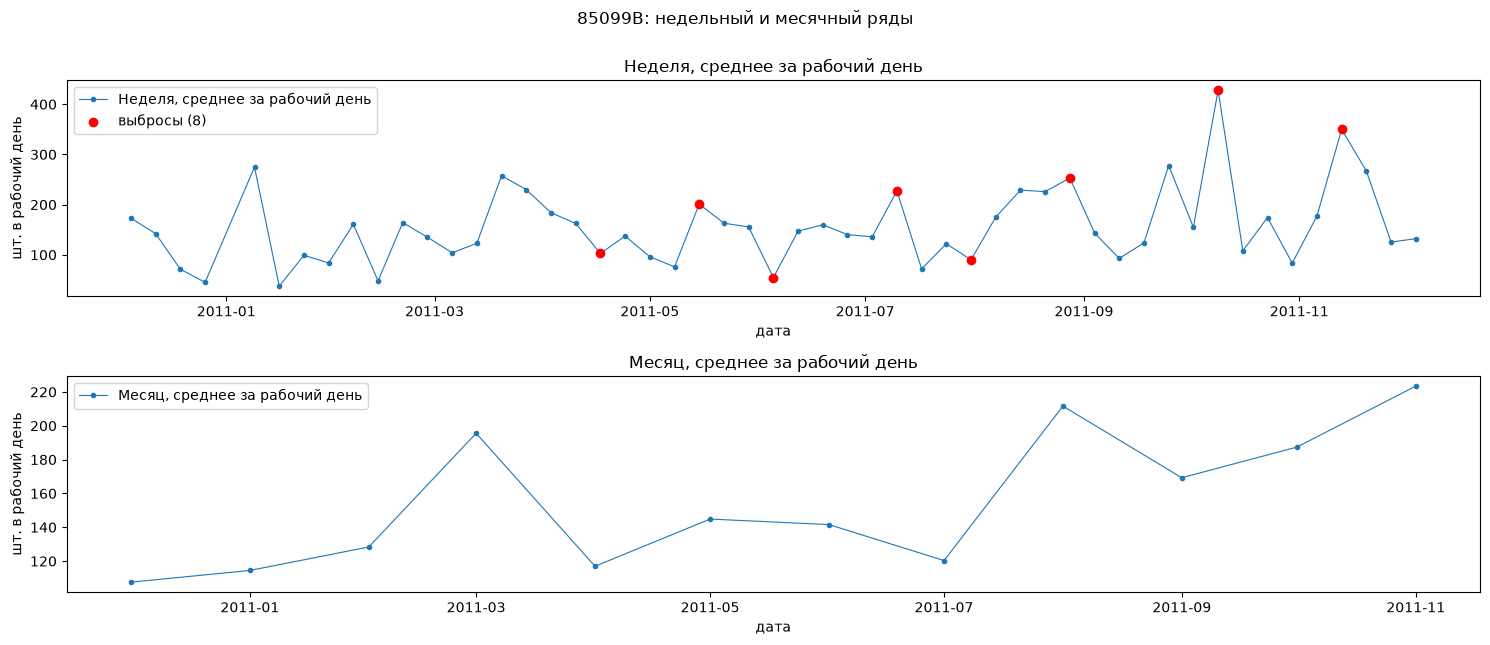

In [19]:
wk = weekly.per_day.dropna()
out_week = {"Неделя, среднее за рабочий день": rt.hampel_outliers(wk, window=5) | rt.iqr_outliers(wk)}
rt.plot_series({"Неделя, среднее за рабочий день": wk, "Месяц, среднее за рабочий день": monthly.per_day},
               outliers=out_week, title=f"{CODE}: недельный и месячный ряды", ylabel="шт. в рабочий день");

Что стоит за крупнейшими дневными значениями:

In [20]:
top_days = obs.nlargest(5).index
(sales[(sales.StockCode == CODE) & sales.date.isin(top_days)]
 .nlargest(8, "Quantity")[["InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice", "CustomerID", "Country"]])

,InvoiceNo,InvoiceDate,Quantity,UnitPrice,CustomerID,Country
121857,546789,2011-03-17 10:17:00,1200,1.65,15769.0,United Kingdom
380505,569815,2011-10-06 11:53:00,1000,1.79,15838.0,United Kingdom
454472,575582,2011-11-10 11:55:00,1000,1.79,16986.0,United Kingdom
465306,576219,2011-11-14 12:58:00,400,1.79,15838.0,United Kingdom
311678,564312,2011-08-24 12:52:00,300,1.79,15769.0,United Kingdom
311668,564310,2011-08-24 12:51:00,200,1.79,15769.0,United Kingdom
311672,564311,2011-08-24 12:52:00,200,1.79,15769.0,United Kingdom
381313,569857,2011-10-06 14:31:00,200,1.95,12939.0,United Kingdom


- Всплески дают **крупные оптовые заказы** (1000–1200 шт.) от постоянных клиентов: 15769 заказывает по 400 шт. регулярно, значит это реальный спрос.
- Хампель находит больше точек: ряд «рваный», локальный разброс мал. IQR отмечает в основном самые крупные заказы.
- **Решение:** выбросы **не удаляем и не правим** — оптовые заказы составляют часть спроса этого товара. Их влияние на анализ смягчаем преобразованием Box–Cox (блок 5) и робастной STL (блок 4).

## 3. Описательный анализ
### 3.1 Статистики по частотам

In [21]:
rt.describe_series({"день": daily, "неделя (за раб. день)": weekly.per_day, "месяц (за раб. день)": monthly.per_day})

,день,неделя (за раб. день),месяц (за раб. день)
n,297.00,52.00,12.00
mean,157.33,155.69,155.11
median,102.00,142.70,143.21
std,185.30,77.60,40.82
CV,1.18,0.50,0.26
min,0.00,37.50,107.55
max,1443.00,428.17,223.42
skew,3.08,1.17,0.49
kurtosis,14.37,2.10,-1.32


- Среднее — около 155 шт. в рабочий день на всех частотах (агрегация уровень не меняет).
- **Дневной ряд очень неоднородный:** CV ≈ 1.2, скошенность ≈ 3, тяжёлый правый хвост (оптовые заказы). Медиана (102) намного меньше среднего (157).
- При агрегации шум усредняется: CV падает до 0.5 у недельного ряда и до 0.26 у месячного.

### 3.2 Уровень и разброс во времени

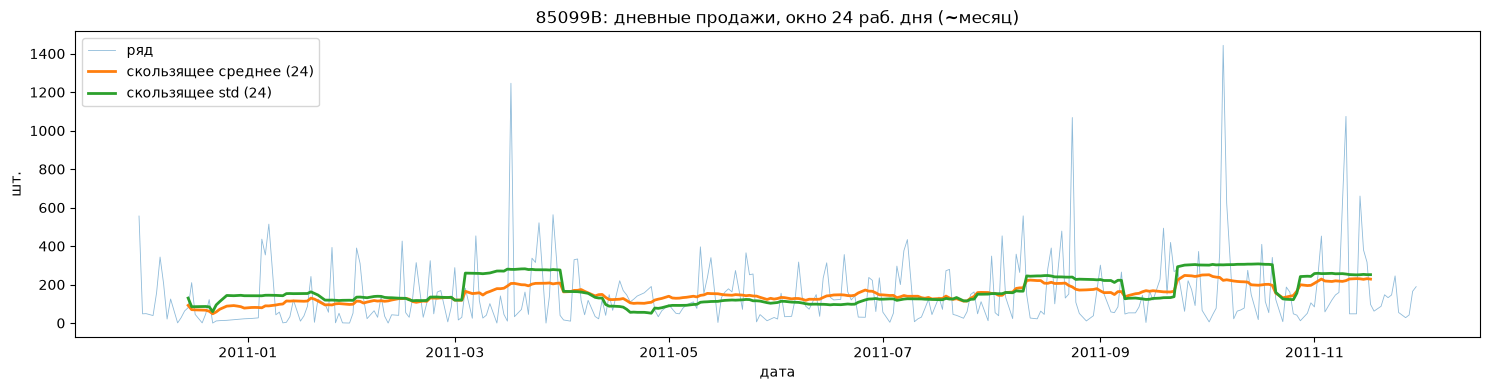

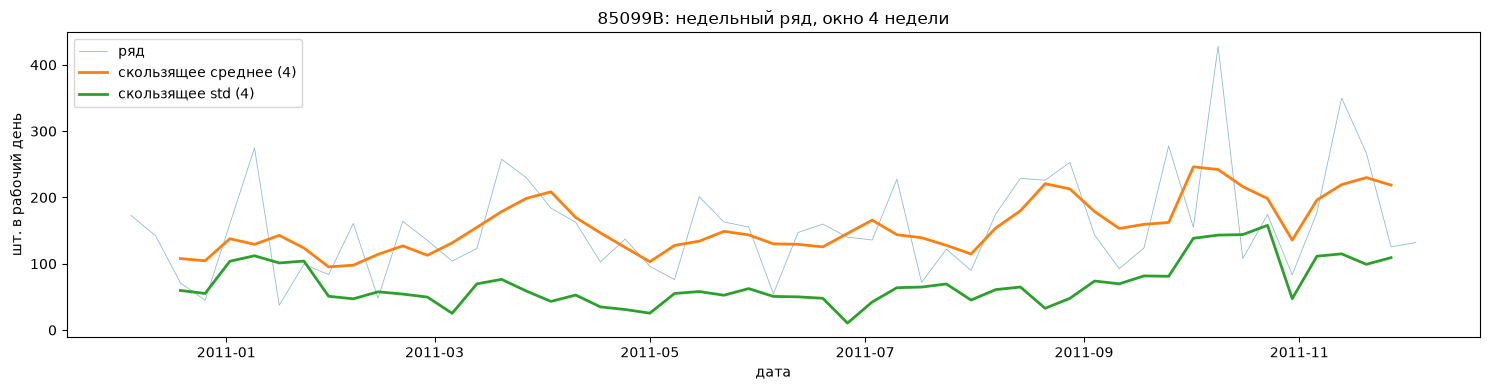

In [22]:
rt.plot_rolling(daily_f, 24, f"{CODE}: дневные продажи, окно 24 раб. дня (~месяц)");
rt.plot_rolling(weekly_f, 4, f"{CODE}: недельный ряд, окно 4 недели", ylabel="шт. в рабочий день");

In [23]:
ls = rt.level_spread(daily)
print(f"Корреляция месячного среднего и std: {ls['mean'].corr(ls['std']):.2f}")
ls

Корреляция месячного среднего и std: 0.80


,mean,std,CV
date,,,
2010-12-01,107.55,137.44,1.28
2011-01-01,114.46,153.57,1.34
2011-02-01,128.33,128.47,1.00
2011-03-01,195.56,267.31,1.37
2011-04-01,116.95,93.08,0.80
2011-05-01,144.84,115.42,0.80
2011-06-01,141.58,95.80,0.68
2011-07-01,120.31,119.49,0.99
2011-08-01,211.62,237.87,1.12


- **Уровень растёт:** со ~110 шт./день зимой до ~220 в ноябре. Рост неравномерный: всплески в марте и августе, просадка в апреле–июле.
- Скользящее std меняется ступеньками: когда один крупный заказ входит в окно или выходит из него, std резко подскакивает или падает. Дневной разброс определяют оптовые заказы.
- **Разброс растёт вместе с уровнем:** корреляция среднего и std по месяцам ≈ 0.8, при этом CV остаётся примерно на одном уровне. Это признак **мультипликативной** структуры, поэтому для стабилизации дисперсии подойдёт логарифм (блок 5).

### 3.3 Профиль по дням недели

Краскел–Уоллис: H = 44.1, p-value = 2.2e-08


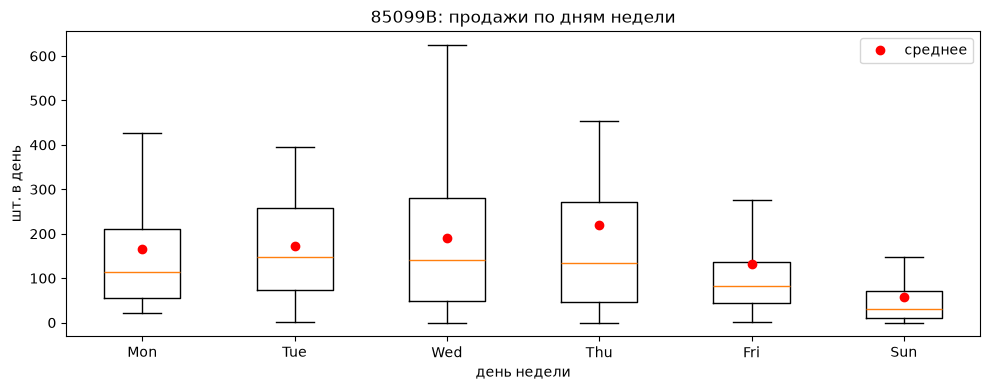

In [24]:
rt.plot_weekday_profile(daily, f"{CODE}: продажи по дням недели");
res = rt.weekday_kruskal(daily)
print(f"Краскел–Уоллис: H = {res.statistic:.1f}, p-value = {res.pvalue:.1e}")

- **Воскресенье почти в 3 раза слабее будней** (среднее ≈ 58 против 130–220). Пик — середина недели (вт–чт).
- Тест Краскела–Уоллиса (непараметрический, т.к. распределения скошены): p ≪ 0.05 → распределения продаж по дням недели **различаются**. Это кандидат в недельную сезонность с периодом 6 (проверим в блоке 4).

### 3.4 Автокорреляция

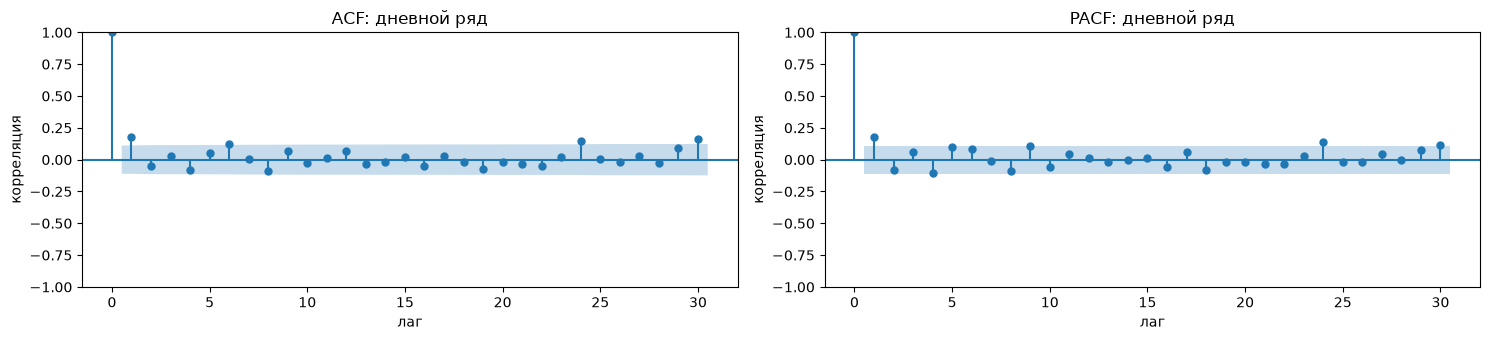

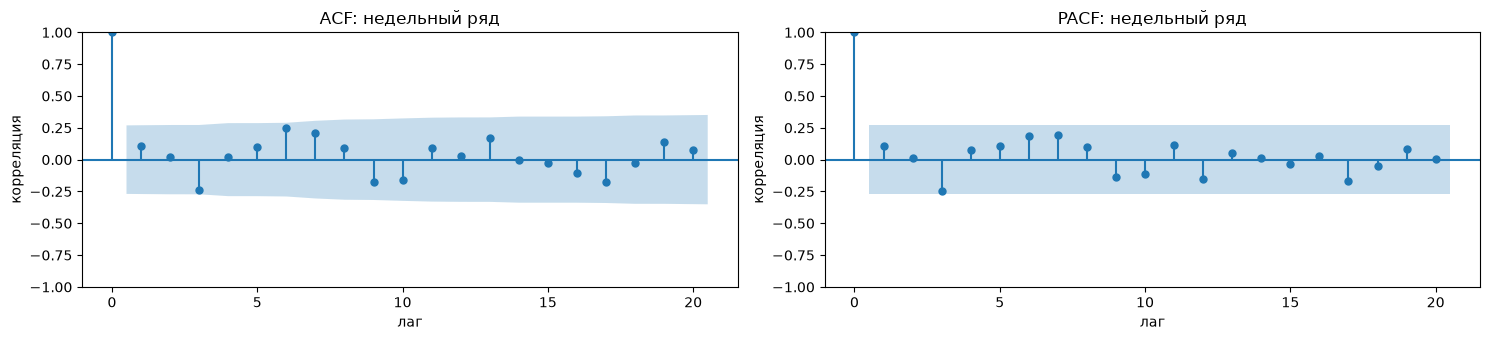

In [25]:
rt.plot_acf_pacf(daily_f, 30, "дневной ряд");
rt.plot_acf_pacf(weekly_f, 20, "недельный ряд");

- **Дневной ряд:** автокорреляции слабые (лаг 1 ≈ 0.18, лаг 6 ≈ 0.12): дневной шум от оптовых заказов маскирует связь между днями. Пик на лаге 6 — слабый след недельного цикла.
- **Недельный ряд:** значимых лагов почти нет, длинной памяти нет. Медленного затухания ACF, типичного для сильного тренда, не видно, — проверим формально в блоке 5.

### 3.5 Из чего складываются продажи

In [26]:
rt.order_profile(sales, CODE)

,чеков,клиентов,шт,шт_на_чек
date,,,,
2010-12-01,119,77,2151,18.1
2011-01-01,119,73,2747,23.1
2011-02-01,123,78,3080,25.0
2011-03-01,171,106,5280,30.9
2011-04-01,122,83,2456,20.1
2011-05-01,186,122,3621,19.5
2011-06-01,181,115,3681,20.3
2011-07-01,183,118,3128,17.1
2011-08-01,177,134,5502,31.1


- **Рост продаж идёт за счёт числа покупателей:** чеков стало вдвое больше (119 → 246), клиентов — 77 → 171.
- Средний размер чека стабилен (≈ 20–25 шт., медианная строка — 10 шт.), кроме марта и августа: там его поднимают единичные оптовые заказы.

## 4. Декомпозиция и сезонность
### 4.1 Какие сезонности вообще можно проверить

| Ряд | Возможный сезонный период | Длина ряда | Можно проверить? |
|---|---|---|---|
| День | неделя = 6 рабочих дней | 313 дней ≈ 52 периода | **да** |
| Неделя | год = 52 недели | 53 недели ≈ 1 период | нет |
| Месяц | год = 12 месяцев | 12 месяцев = 1 период | нет |

Для оценки сезонности нужно ≥ 2 полных периода. Годовую сезонность (например, предрождественский рост) по этим данным **не установить**: подъём осенью неотличим от тренда. Поэтому декомпозируем дневной ряд с периодом 6.

### 4.2 STL-разложение дневного ряда
**Метод — STL** (Seasonal-Trend decomposition using LOESS):
- работает с любым периодом, тренд гибкий;
- `robust=True` — оптовые заказы получают низкий вес и не искажают тренд и сезонность;
- разложение `log(1 + y)`: в блоке 3 разброс рос вместе с уровнем (мультипликативная структура), а в логарифмах она становится аддитивной;
- `seasonal=31` — длинное окно: профиль недели почти постоянный и не подстраивается под шум. Короткое окно по умолчанию (7) подгоняет сезонность под случайные колебания.
- `trend=51` (~2 месяца) — окно тренда по умолчанию (~10 дней) повторяло всплески оптовых заказов, а тренд должен показывать долгосрочное направление. Сила сезонности от выбора окна тренда почти не зависит (0.17–0.19).

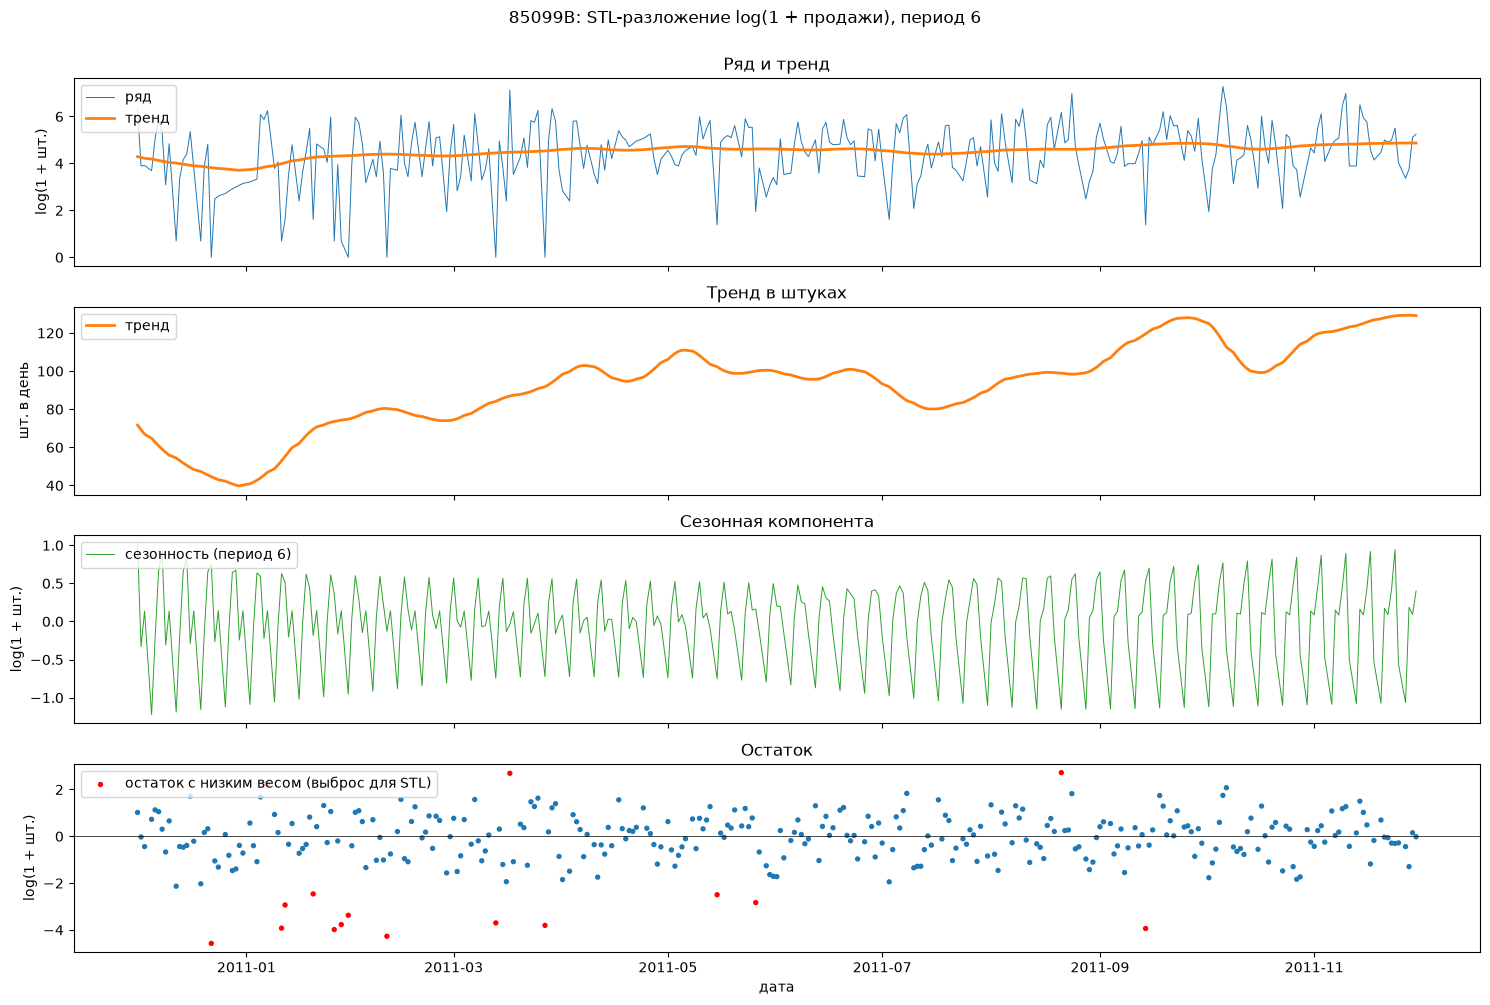

In [27]:
dec = rt.stl_decompose(daily_f, period=6, seasonal=31, trend=51)
rt.plot_decomposition(dec, f"{CODE}: STL-разложение log(1 + продажи), период 6");

- **Тренд** растёт с ~40–70 шт./день зимой (минимум — на Рождество) до ~130 в ноябре. Рост идёт с провалом в июле (~80). В штуках тренд ниже среднего из блока 3, потому что после логарифма он ближе к медиане, а не к среднему.
- **Сезонная компонента** — регулярный недельный узор. Амплитуда меняется: в начале и в конце года она больше, летом меньше.
- **Остаток** большой — основная часть дневной изменчивости шумовая. Красные точки — дни, которые робастная STL сочла выбросами. В основном это **почти нулевые дни**: в логарифме продажа 0–2 шт. даёт большое отрицательное отклонение. Крупных заказов среди них меньше.

### 4.3 Насколько сильна сезонность

In [28]:
rt.strength(dec)

сила тренда F_T        0.094
сила сезонности F_S    0.173
dtype: float64

Сила компоненты по Hyndman: 0 — компоненты нет, 1 — она объясняет всё, кроме остатка.
Оба значения небольшие: шум доминирует в дневном ряде. Тренд за год удваивает уровень, но на фоне дневных скачков это объясняет мало дисперсии (F_T ≈ 0.1).
F_S > 0 бывает и у чистого шума, поэтому нужно сравнение с рядом **без сезонности**.

In [29]:
rt.seasonality_permutation_test(daily_f, n=200, period=6, seasonal=31, trend=51)

F_S                      0.173
F_S перемешанных, 95%    0.085
p-value                  0.000
dtype: float64

**Перестановочный тест:** дни перемешиваются случайно — порядок дней недели разрушается, а распределение значений остаётся тем же. У 95 % перемешанных рядов F_S ≤ ~0.09, у реального — 0.17, p < 0.01. Недельная сезонность **не случайна**.

### 4.4 Профиль недели и его устойчивость

In [30]:
display(rt.seasonal_factors(dec))
rt.seasonal_factors(dec, split="2011-06-01")

date
Monday       1.08
Tuesday      1.48
Wednesday    1.43
Thursday     1.30
Friday       0.90
Sunday       0.38
Name: seasonal, dtype: float64

,до 2011-06-01,после 2011-06-01
date,,
Monday,1.09,1.07
Tuesday,1.78,1.22
Wednesday,1.27,1.60
Thursday,0.92,1.83
Friday,1.08,0.74
Sunday,0.41,0.34


Коэффициенты мультипликативные: 0.38 — день продаёт 38 % от типичного.
- **Воскресенье — ×0.4** в обеих половинах года (0.41 и 0.34). Это устойчивая часть сезонности.
- Пик внутри недели **неустойчив:** до июня — вторник, после — среда–четверг. На него нельзя полагаться как на сезонный эффект.

### 4.5 Остаток

,lb_stat,lb_pvalue
6,13.693112,0.033259
12,17.106128,0.145649


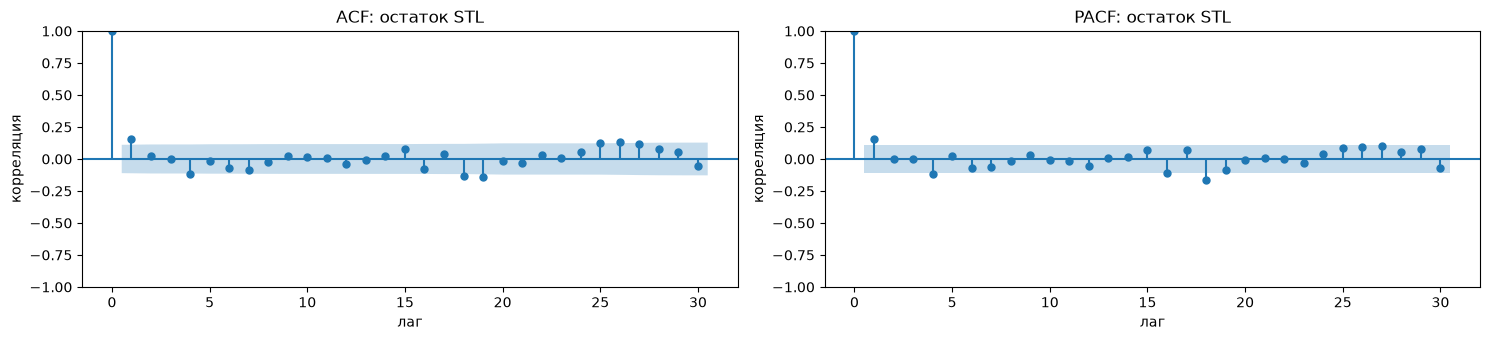

In [31]:
from statsmodels.stats.diagnostic import acorr_ljungbox
display(acorr_ljungbox(dec.resid, lags=[6, 12]))
rt.plot_acf_pacf(dec.resid, 30, "остаток STL");

Тест Льюнга–Бокса: H0 — автокорреляций в остатке нет.
- До лага 12 p > 0.05 → длинной зависимости в остатке нет. Тренд и сезонность забрали основную структуру.
- До лага 6 p ≈ 0.03 → осталась слабая краткосрочная зависимость (лаг 1): крупные заказы иногда идут сериями по 2–3 дня. Гладкий тренд это не описывает, и это не сезонность. Такую зависимость учтёт модель прогноза (AR-часть).

### 4.6 Вывод о сезонности
**Недельная сезонность с периодом 6 рабочих дней есть, но слабая.** Её подтверждают четыре независимых признака:
1. Тест Краскела–Уоллиса по дням недели: p ≈ 2·10⁻⁸ (блок 3).
2. Сила сезонности F_S = 0.17 выше, чем у 95 % перемешанных рядов (p < 0.01).
3. Пик ACF на лаге 6 (блок 3).
4. Воскресный провал (×0.4) повторяется в обеих половинах года.

Сезонность сводится в основном к **провалу в воскресенье**. Годовую сезонность на 12 месяцах данных проверить нельзя.

## 5. Стационарность
Стационарный ряд — ряд, у которого среднее, дисперсия и автокорреляции не меняются во времени. Используем два теста с **противоположными** нулевыми гипотезами:
- **ADF** (Dickey–Fuller): H0 — есть единичный корень (ряд нестационарен). p < 0.05 → отвергаем H0.
- **KPSS**: H0 — ряд стационарен вокруг константы (`c`) или вокруг линейного тренда (`ct`). p < 0.05 → отвергаем H0.

| ADF | KPSS (c) | KPSS (ct) | Вывод |
|---|---|---|---|
| отвергает | не отвергает | — | стационарен |
| отвергает (ct) | отвергает | не отвергает | **тренд-стационарен**: тренд детерминированный, достаточно его вычесть |
| не отвергает | отвергает | — | единичный корень: нужно дифференцирование |

p-value KPSS табличный и обрезан до [0.01, 0.1]: значение 0.1 означает «≥ 0.1».

### 5.1 Исходные ряды

In [32]:
rt.stationarity_tests({"день": daily_f, "неделя": weekly_f, "месяц": monthly_f})

,n,ADF p (c),ADF p (ct),KPSS p (c),KPSS p (ct),acf1,вывод
день,313,0.000012,0.000002,0.01345,0.1,0.178405,тренд-стационарен
неделя,53,0.705714,0.000001,0.036413,0.1,0.104061,тренд-стационарен
месяц,12,0.994635,0.0,0.037035,0.1,0.157856,тренд-стационарен


- **День и неделя — тренд-стационарны.** ADF отвергает единичный корень (для недели — только с трендом в регрессии), KPSS отвергает стационарность вокруг константы, но не вокруг тренда. Уровень ряда растёт, но это детерминированный тренд, а не «случайное блуждание».
- **Месяц:** 12 точек — для тестов этого слишком мало: ADF не успевает оценить даже свои лаги. Результат формально тот же, но выводы по месячному ряду делаем только по графику и не преобразуем его.

Значит, ряд нужно привести к стационарному виду: **стабилизировать дисперсию** (она росла с уровнем, блок 3) и **убрать тренд**.

### 5.2 Стабилизация дисперсии

In [33]:
daily_bc, lam_d = rt.boxcox(daily_f)
weekly_bc, lam_w = rt.boxcox(weekly_f)
print(f"Box–Cox λ: день {lam_d:.2f}, неделя {lam_w:.2f}  (λ=0 — логарифм, λ=0.5 — корень)")
display(rt.variance_check({"день: исходный": daily_f, "день: log(1+y)": np.log1p(daily_f), "день: Box–Cox": daily_bc}))
rt.variance_check({"неделя: исходный": weekly_f, "неделя: log(1+y)": np.log1p(weekly_f), "неделя: Box–Cox": weekly_bc}, freq="QS")

Box–Cox λ: день 0.21, неделя 0.25  (λ=0 — логарифм, λ=0.5 — корень)


,"corr(mean, std)",std max/min,skew
день: исходный,0.78,3.41,3.14
день: log(1+y),-0.77,2.21,-0.89
день: Box–Cox,-0.40,1.89,-0.01


,"corr(mean, std)",std max/min,skew
неделя: исходный,0.80,2.64,1.18
неделя: log(1+y),-0.47,1.65,-0.39
неделя: Box–Cox,-0.02,1.62,0.00


Хорошее преобразование даёт corr(mean, std) ≈ 0, а std max/min — ближе к 1.
- У исходного ряда разброс растёт с уровнем (corr ≈ 0.8).
- **Логарифм на дневном ряде перекорректирует** (corr ≈ −0.8): почти нулевые дни в log-шкале становятся большими отрицательными выбросами, и в слабых месяцах разброс растёт.
- **Box–Cox** с λ, подобранным по правдоподобию (≈ 0.2 — между логарифмом и корнем), даёт симметричное распределение (skew ≈ 0) и самую ровную дисперсию. Выбираем его.

### 5.3 Удаление тренда: вычитание тренда или дифференцирование

In [34]:
daily_st, slope_d = rt.detrend_linear(daily_bc)
weekly_st, slope_w = rt.detrend_linear(weekly_bc)
rt.stationarity_tests({
    "день: Box–Cox": daily_bc,
    "день: Box–Cox − линейный тренд": daily_st,
    "день: Box–Cox, разность 1": daily_bc.diff(),
    "день: Box–Cox, сезонная разность 6": daily_bc.diff(6),
    "неделя: Box–Cox": weekly_bc,
    "неделя: Box–Cox − линейный тренд": weekly_st,
    "неделя: Box–Cox, разность 1": weekly_bc.diff(),
})

,n,ADF p (c),ADF p (ct),KPSS p (c),KPSS p (ct),acf1,вывод
день: Box–Cox,313,0.000001,0.0,0.01,0.1,0.208703,тренд-стационарен
день: Box–Cox − линейный тренд,313,0.0,0.0,0.1,0.1,0.157836,стационарен
"день: Box–Cox, разность 1",312,0.0,0.0,0.1,0.1,-0.370845,стационарен
"день: Box–Cox, сезонная разность 6",307,0.0,0.0,0.1,0.1,0.219128,стационарен
неделя: Box–Cox,53,0.000151,0.000002,0.03087,0.1,0.092496,тренд-стационарен
неделя: Box–Cox − линейный тренд,53,0.0,0.000002,0.1,0.1,-0.029407,стационарен
"неделя: Box–Cox, разность 1",52,0.02246,0.096911,0.1,0.1,-0.448018,стационарен


- Тесты проходят **все** варианты: и вычитание тренда, и дифференцирование. Различает их **acf1**:
  - после вычитания тренда acf1 ≈ 0.16 (день) и ≈ −0.03 (неделя) — небольшая естественная связь соседних наблюдений;
  - после первой разности acf1 ≈ −0.4…−0.45 — это **передифференцирование**. Разность тренд-стационарного ряда искусственно создаёт отрицательную связь соседних точек и добавляет шум.
- Сезонная разность (лаг 6) тоже не нужна: сезонность слабая (блок 4), а разность удваивает дисперсию шума.

**Решение:** Box–Cox + вычитание линейного тренда. Дифференцирование не применяем: тесты из 5.1 показали, что единичного корня нет.

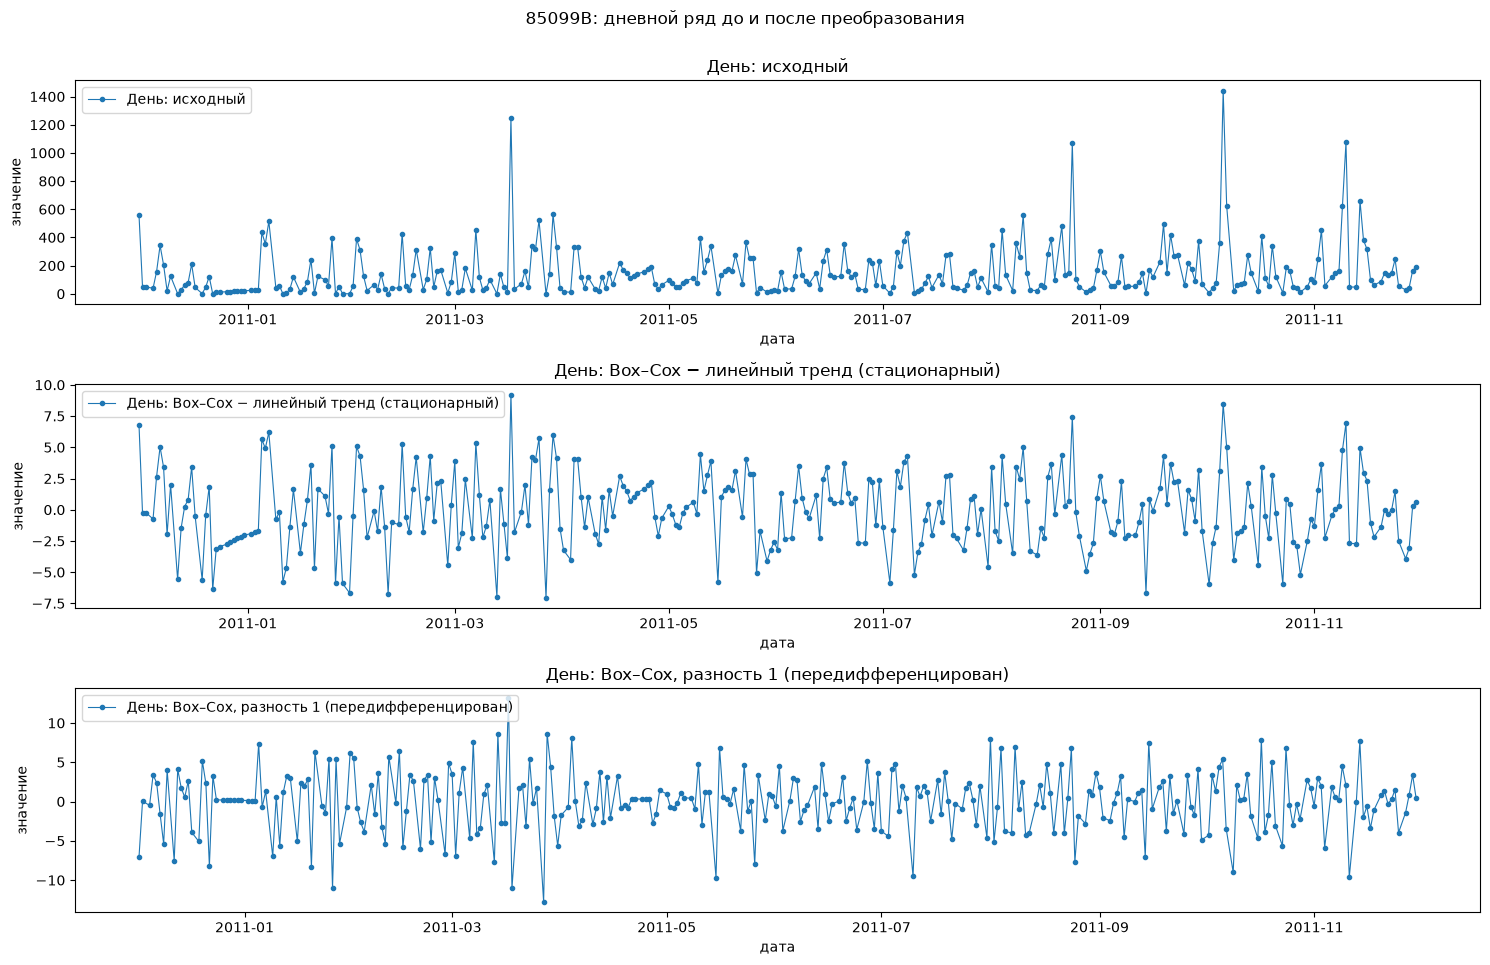

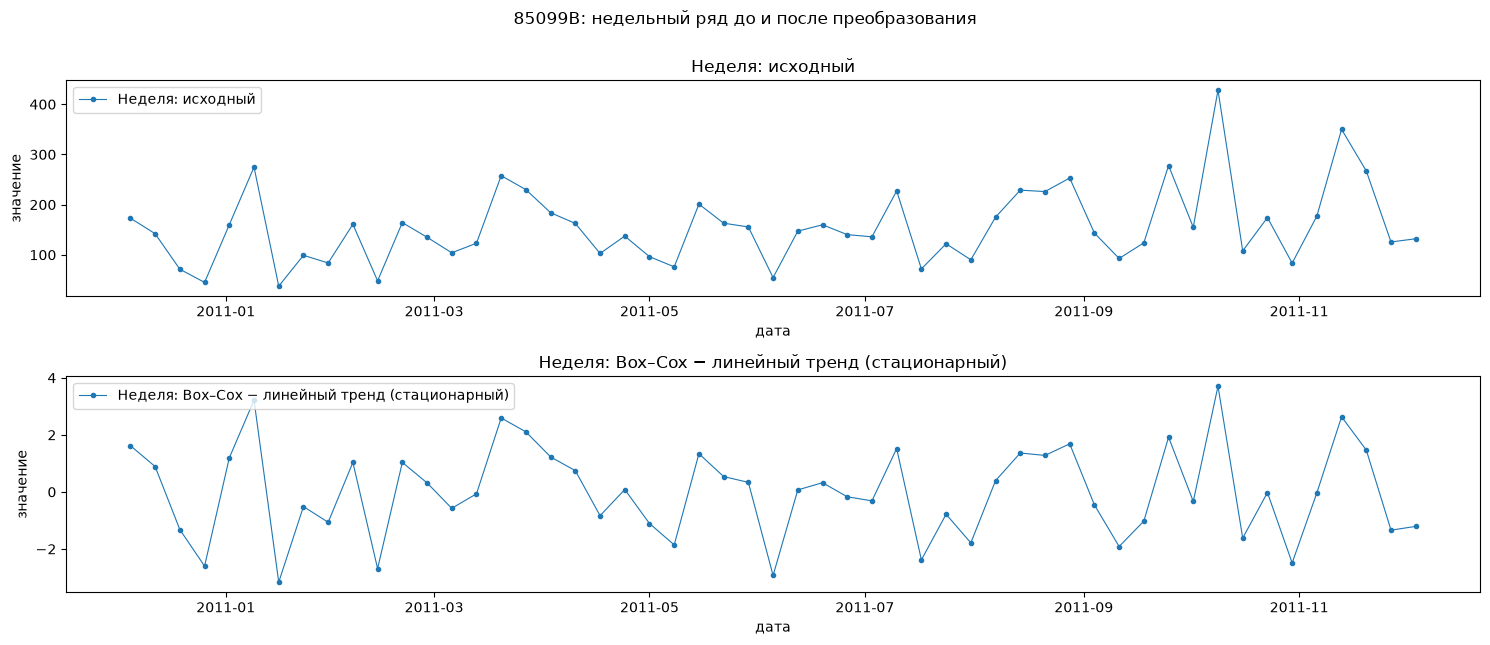

In [35]:
rt.plot_series({"День: исходный": daily_f,
                "День: Box–Cox − линейный тренд (стационарный)": daily_st,
                "День: Box–Cox, разность 1 (передифференцирован)": daily_bc.diff()},
               title=f"{CODE}: дневной ряд до и после преобразования", ylabel="значение");
rt.plot_series({"Неделя: исходный": weekly_f,
                "Неделя: Box–Cox − линейный тренд (стационарный)": weekly_st},
               title=f"{CODE}: недельный ряд до и после преобразования", ylabel="значение");

После преобразования уровень и разброс ряда постоянны во времени. Прямые участки в конце декабря и в конце апреля — интерполированные праздники.
Для модели прогноза ряд восстанавливается обратно: прибавить тренд → обратный Box–Cox → вычесть 1.

## Итог
- **Данные:** очищены от отмен-ошибок, списаний и служебных кодов. Учтён календарь магазина: суббот нет, праздники — пропуски, а не нули. Анализируется период 01.12.2010–30.11.2011.
- **Ряд 85099B:** спрос регулярный (нулей < 2 %), но «рваный» из-за оптовых заказов. Выбросы — реальные заказы, оставлены.
- **Тренд:** продажи за год выросли примерно вдвое, за счёт числа покупателей, а не размера чека.
- **Сезонность:** недельная (период 6 рабочих дней) — слабая, но статистически значимая, и в основном это провал в воскресенье (×0.4). Годовую сезонность на 12 месяцах проверить нельзя.
- **Стационарность:** дневной и недельный ряды тренд-стационарны. Для приведения к стационарному виду — Box–Cox (λ ≈ 0.2) и вычитание линейного тренда. Дифференцирование приводит к передифференцированию.